# Chapter 60: Growth Accounting, Accumulation, and Convergence

This notebook reruns four worked examples from the chapter: the Solow transition toward a steady state, the golden rule of accumulation, conditional convergence and the Solow residual. Every example uses the book's hypothetical teaching numbers, not data from any real economy; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def pct(fraction, digits=1):
    """Percent from a fraction: pct(0.022) -> '2.2%'."""
    return f"{num(100 * float(fraction), digits)}%"


def solow_steady_state(s, alpha, ndg):
    """Steady state of y = k^alpha: k* = (s / ndg)^(1 / (1 - alpha)), y* = k*^alpha.

    solow-swan-convergence-mechanism (chapter 60): s 0.24, alpha 0.40, ndg 0.06 gives
    k* = 10.079, y* = 2.520 and investment = break-even = 0.605.
    """
    k = (s / ndg) ** (1.0 / (1.0 - alpha))
    y = k ** alpha
    return {"k": k, "y": y, "investment": s * y, "break_even": ndg * k}


def solow_kdot(k, s, alpha, ndg):
    """Net change k-dot = s k^alpha - ndg k, with its parts and its share of k.

    solow-swan-convergence-mechanism (chapter 60): k 4 gives 0.418 - 0.240 = 0.178 (4.45
    percent of k); k 16 gives 0.728 - 0.960 = -0.232 (-1.45 percent).
    """
    y = k ** alpha
    inv = s * y
    be = ndg * k
    kdot = inv - be
    return {"y": y, "investment": inv, "break_even": be, "kdot": kdot, "share": kdot / k}


def golden_rule(alpha, ndg):
    """Golden-rule stock of f(k) = k^alpha: alpha k^(alpha - 1) = ndg.

    golden-rule-of-accumulation (chapter 60): alpha 0.40, ndg 0.08 gives k_GR = 5^(1/0.6)
    = 14.620, output 2.924, break-even 1.170, consumption 1.754, saving rate 0.40.
    """
    k = (alpha / ndg) ** (1.0 / (1.0 - alpha))
    y = k ** alpha
    return {"k": k, "y": y, "break_even": ndg * k, "c": y - ndg * k, "s": ndg * k / y}


def steady_consumption(k, alpha, ndg):
    """Steady consumption c(k) = k^alpha - ndg k, with output, break-even and MPK.

    golden-rule-of-accumulation (chapter 60): k 9 gives 2.408 - 0.720 = 1.688 (MPK 0.107);
    k 25 gives 3.624 - 2.000 = 1.624 (MPK 0.058).
    """
    y = k ** alpha
    be = ndg * k
    return {"y": y, "break_even": be, "c": y - be, "mpk": alpha * k ** (alpha - 1.0)}


def conditional_convergence(y0, y_star, lam):
    """Transition growth g = lam ln(y* / y0), in log units.

    conditional-convergence (chapter 60): 15,000 to 30,000 at lam 0.15 gives 0.1040;
    to 18,000 gives 0.02735; to 27,000 gives 0.08817.
    """
    return lam * math.log(y_star / y0)


def solow_residual(gY, gK, gL, alpha, exact=False):
    """Residual g_A = g_Y - alpha g_K - (1 - alpha) g_L; growth rates in percent.

    exact=False: percentage-point approximation, returns percentage points.
    exact=True: log changes ln(1 + g/100), returns log units.
    solow-residual (chapter 60): 7, 9, 1.5, alpha 0.35 gives inputs 3.15 + 0.975 = 4.125 and
    residual 2.875 points; exact 0.027819; with labor 2.5 the residual is 2.225 (exact 0.021446).
    """
    if exact:
        lY, lK, lL = (math.log(1 + g / 100.0) for g in (gY, gK, gL))
        return lY - alpha * lK - (1 - alpha) * lL
    return gY - alpha * gK - (1 - alpha) * gL


plt.rcParams.update(HOUSE_RC)


growth = SimpleNamespace(solow_steady_state=solow_steady_state, solow_kdot=solow_kdot, golden_rule=golden_rule, steady_consumption=steady_consumption, conditional_convergence=conditional_convergence, solow_residual=solow_residual)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'solow-swan-convergence-mechanism': {'alpha': 0.4,
                                      's': 0.24,
                                      'ndg': 0.06,
                                      'k_star': 10.079,
                                      'y_star': 2.52,
                                      'inv_star': 0.605,
                                      'k_low': 4,
                                      'y_low': 1.741,
                                      'inv_low': 0.418,
                                      'be_low': 0.24,
                                      'kdot_low': 0.178,
                                      'share_low_pct': 4.45,
                                      'k_high': 16,
                                      'y_high': 3.031,
                                      'inv_high': 0.728,
                                      'be_high': 0.96,
                                      'kdot_high': -0.232,
                                      'share_high_pct': -1.45},
 'golden-rule-of-accumulation': {'alpha': 0.4,
                                 'ndg': 0.08,
                                 'k_gr': 14.62,
                                 'y_gr': 2.924,
                                 'be_gr': 1.17,
                                 'c_gr': 1.754,
                                 's_gr': 0.4,
                                 'k9': {'y': 2.408, 'be': 0.72, 'c': 1.688, 'mpk': 0.107},
                                 'k25': {'y': 3.624, 'be': 2.0, 'c': 1.624, 'mpk': 0.058}},
 'conditional-convergence': {'y0': 15000,
                             'lam': 0.15,
                             'y_east': 30000,
                             'g_east': 0.104,
                             'y_west': 18000,
                             'g_west': 0.02735,
                             'y_west_reformed': 27000,
                             'g_west_reformed': 0.08817},
 'solow-residual': {'alpha': 0.35,
                    'gY': 7,
                    'gK': 9,
                    'gL': 1.5,
                    'inputs': 4.125,
                    'residual': 2.875,
                    'exact': 0.027819,
                    'gL_revised': 2.5,
                    'inputs_revised': 4.775,
                    'residual_revised': 2.225,
                    'exact_revised': 0.021446},
 'constructed': {'solow-swan-convergence-mechanism': {'s': [0.12, 0.36]},
                 'golden-rule-of-accumulation': {'ndg': [0.06, 0.1]},
                 'conditional-convergence': {'lam': [0.1, 0.2]},
                 'solow-residual': {'gL': [3.5], 'alpha': [0.25, 0.45]}}}


def kf(k):
    """Capital level: whole numbers without decimals, others to three decimals."""
    return num(k, 0) if float(k).is_integer() else num(k, 3)


PROV = "Constructed teaching numbers, not data from any real economy."


def solow_picture(s=0.24, k0=4):
    b = BV["solow-swan-convergence-mechanism"]
    alpha, ndg = b["alpha"], b["ndg"]
    ss = growth.solow_steady_state(s, alpha, ndg)
    r = growth.solow_kdot(k0, s, alpha, ndg)
    kdot = r["kdot"]
    at_rest = abs(kdot) < 0.0005
    fig, ax = new_figure()
    ks = np.linspace(0.01, 24, 300)
    ax.plot(ks, s * ks ** alpha, color=PALETTE["teal"], linewidth=2.2)
    ax.plot(ks, ndg * ks, color=PALETTE["ink"], linewidth=1.8, linestyle="dashed")
    label(ax, 23, s * 23 ** alpha, f"investment {num(s, 2)} k^0.40", col="teal", dx=-4, dy=6, ha="right")
    label(ax, 23, ndg * 23, "break-even 0.06k", col="ink", dx=-4, dy=-14, ha="right", va="top")
    vline(ax, ss["k"], f"k* = {num(ss['k'], 3)}", col="grey", y_frac=0.97,
          ha="right" if ss["k"] > 16 else "left")
    mark(ax, k0, r["investment"], None, col="teal")
    mark(ax, k0, r["break_even"], None, col="ink")
    if not at_rest:
        ax.annotate("", xy=(k0 + (1.6 if kdot > 0 else -1.6), 0.08), xytext=(k0, 0.08),
                    arrowprops={"arrowstyle": "->", "color": PALETTE["terracotta"], "lw": 2.2})
    label(ax, k0, max(r["investment"], r["break_even"]), f"k0 = {kf(k0)}: k-dot = {num(kdot, 3)}",
          col="terracotta", dx=-6 if k0 > 12 else 6, dy=10, ha="right" if k0 > 12 else "left")
    ax.set_xlim(0, 24)
    ax.set_ylim(0, 1.6)
    ax.set_xlabel("Capital per effective worker k")
    ax.set_ylabel("Investment per effective worker")
    if at_rest:
        verdict = ("k0 = 10.079 is k* rounded to three decimals, so the economy is at its steady state and "
                   "capital per effective worker stays put")
        direction = "stays at its steady state"
    elif kdot > 0:
        verdict = "investment exceeds break-even needs, so capital per effective worker rises toward k*"
        direction = "grows"
    else:
        verdict = "break-even needs exceed investment, so capital per effective worker falls toward k*"
        direction = "shrinks"
    metrics = {"Steady state k*": num(ss["k"], 3), "Steady output y*": num(ss["y"], 3),
               "Output at k0": num(r["y"], 3), "Investment at k0": num(r["investment"], 3),
               "Break-even at k0": num(r["break_even"], 3), "k-dot": num(kdot, 3),
               "k-dot as share of k0": pct(r["share"], 2), "Capital": direction}
    ratio = s / ndg
    dp = 5 if at_rest else 4  # at rest, 4 decimals would show 0.6048 - 0.6047 = 0.000
    kd_dp = 5 if at_rest else 3
    steps = [f"k* = ({num(s, 2)} / 0.06)^(1/0.60) = {num(ratio, 0)}^(5/3) = {num(ss['k'], 3)}",
             f"y* = {num(ss['k'], 3)}^0.40 = {num(ss['y'], 3)}",
             f"Output at k0: {kf(k0)}^0.40 = {num(r['y'], 4)}",
             f"Investment = {num(s, 2)} x {num(r['y'], 4)} = {num(r['investment'], dp)}",
             f"Break-even = 0.06 x {kf(k0)} = {num(r['break_even'], dp)}",
             f"k-dot = {num(r['investment'], dp)} - {num(r['break_even'], dp)} = {num(kdot, kd_dp)}, "
             f"or {pct(r['share'], 2)} of k0"]
    interp = (f"With s = {num(s, 2)} the target is k* = {num(ss['k'], 3)}. At k0 = {kf(k0)} investment is {num(s, 2)} x "
              f"{num(r['y'], 4)} = {num(r['investment'], dp)} and break-even investment is 0.06 x {kf(k0)} = "
              f"{num(r['break_even'], dp)}, so k-dot = {num(r['investment'], dp)} - {num(r['break_even'], dp)} = "
              f"{num(kdot, kd_dp)} ({pct(r['share'], 2)} of k0): {verdict}.")
    alt = (f"Solow diagram with the investment curve {num(s, 2)} k^0.40 and the break-even line 0.06k crossing at "
           f"k* = {num(ss['k'], 3)}. At k0 = {kf(k0)} investment is {num(r['investment'], 3)} and break-even "
           f"{num(r['break_even'], 3)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def golden_picture(k=14.62, ndg=0.08):
    alpha = BV["golden-rule-of-accumulation"]["alpha"]
    gr = growth.golden_rule(alpha, ndg)
    r = growth.steady_consumption(k, alpha, ndg)
    fig, ax = new_figure()
    ks = np.linspace(0.01, 32, 300)
    ax.plot(ks, ks ** alpha, color=PALETTE["navy"], linewidth=2.2)
    ax.plot(ks, ndg * ks, color=PALETTE["ink"], linewidth=1.8, linestyle="dashed")
    cs = ks ** alpha - ndg * ks
    ax.plot(ks, cs, color=PALETTE["teal"], linewidth=2.2)
    label(ax, 31, 31 ** alpha, "output k^0.40", col="navy", dx=-4, dy=6, ha="right")
    label(ax, 31, ndg * 31, f"break-even {num(ndg, 2)}k", col="ink", dx=-4, dy=-14, ha="right", va="top")
    label(ax, 2.5, 2.5 ** alpha - ndg * 2.5, "consumption c(k)", col="teal", dx=6, dy=-16, va="top")
    ax.plot([k, k], [r["break_even"], r["y"]], color=PALETTE["gold"], linewidth=5, solid_capstyle="butt")
    mark(ax, k, r["c"], f"c = {num(r['c'], 3)} at k = {kf(k)}", col="gold", dx=-8 if k > 20 else 8, dy=-14,
         va="top", ha="right" if k > 20 else "left")
    mark(ax, gr["k"], gr["c"], f"golden rule {num(gr['k'], 3)}", col="teal", dx=-8, dy=8, ha="right")
    ax.set_xlim(0, 32)
    ax.set_ylim(0, 4.4)
    ax.set_xlabel("Steady-state capital per effective worker k  (gold bar: consumption)")
    ax.set_ylabel("Per effective worker")
    gap = r["mpk"] - ndg
    if abs(k - gr["k"]) < 0.005:
        where = "at the golden rule"
        verdict = (f"MPK equals the break-even rate (difference {num(gap, 3)} at three decimals), so no "
                   f"steady-state stock gives more consumption")
    elif gap > 0:
        where = "below the golden rule"
        verdict = (f"MPK {num(r['mpk'], 3)} is above {num(ndg, 2)}, so a larger maintained stock would raise "
                   f"consumption")
    else:
        where = "above the golden rule"
        verdict = (f"MPK {num(r['mpk'], 3)} is below {num(ndg, 2)}, so the extra capital costs more to maintain "
                   f"than it adds to output")
    metrics = {"Output": num(r["y"], 3), "Break-even investment": num(r["break_even"], 3),
               "Consumption": num(r["c"], 3), "Saving rate needed": num(r["break_even"] / r["y"], 3),
               "MPK": num(r["mpk"], 3), "Golden-rule k": num(gr["k"], 3), "Golden-rule consumption": num(gr["c"], 3),
               "Position": where}
    steps = [f"Golden rule: 0.40 k^(-0.60) = {num(ndg, 2)}, so k^0.60 = {num(alpha / ndg, 3)} and k_GR = "
             f"{num(gr['k'], 3)}",
             f"Output = {kf(k)}^0.40 = {num(r['y'], 4)}",
             f"Break-even = {num(ndg, 2)} x {kf(k)} = {num(r['break_even'], 4)}",
             f"c = {num(r['y'], 4)} - {num(r['break_even'], 4)} = {num(r['c'], 3)}",
             f"Saving rate = {num(r['break_even'], 4)} / {num(r['y'], 4)} = {num(r['break_even'] / r['y'], 3)}",
             f"MPK = 0.40 x {kf(k)}^(-0.60) = {num(r['mpk'], 3)}"]
    interp = (f"At k = {kf(k)} output is {num(r['y'], 4)} and break-even investment {num(ndg, 2)} x {kf(k)} = "
              f"{num(r['break_even'], 4)}, leaving consumption {num(r['y'], 4)} - {num(r['break_even'], 4)} = "
              f"{num(r['c'], 3)}. With n + g + delta = {num(ndg, 2)} the golden-rule stock is "
              f"{num(gr['k'], 3)} with consumption {num(gr['c'], 3)}. This k is {where}: {verdict}.")
    alt = (f"Output k^0.40, the break-even line {num(ndg, 2)}k and the consumption curve beneath them. At k = "
           f"{kf(k)} the gold bar shows consumption {num(r['c'], 3)}; the consumption curve peaks at the golden "
           f"rule k = {num(gr['k'], 3)} with {num(gr['c'], 3)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


TARGETS = [18_000, 27_000, 30_000]


def convergence_picture(y_star=30_000, lam=0.15):
    y0 = BV["conditional-convergence"]["y0"]
    g = growth.conditional_convergence(y0, y_star, lam)
    gaps = [math.log(t / y0) for t in TARGETS]
    gs = [growth.conditional_convergence(y0, t, lam) for t in TARGETS]
    fig, ax = new_figure()
    xs = np.arange(len(TARGETS))
    cols = [PALETTE["gold"] if t == y_star else PALETTE["light"] for t in TARGETS]
    ax.bar(xs, [100 * v for v in gs], color=cols, width=0.6)
    for x, v, gp in zip(xs, gs, gaps):
        ax.annotate(f"{num(100 * v, 2)}", (x, 100 * v), xytext=(0, 4), textcoords="offset points", ha="center",
                    va="bottom", fontsize=10.5, color=PALETTE["ink"])
    ax.set_xticks(xs, [f"target {num(t, 0)}\nlog gap {num(gp, 4)}" for t, gp in zip(TARGETS, gaps)])
    ax.set_ylim(0, 16)
    ax.set_ylabel("Predicted growth (log points)")
    ax.set_xlabel(f"Same start, 15,000; lambda = {num(lam, 2)}")
    gap = math.log(y_star / y0)
    metrics = {"Starting income": num(y0, 0), "Target income": num(y_star, 0), "Log gap": num(gap, 4),
               "Predicted growth": num(g, 4), "Growth in log points": num(100 * g, 2)}
    steps = [f"Ratio = {num(y_star, 0)} / 15,000 = {num(y_star / y0, 1)}",
             f"Log gap = ln({num(y_star / y0, 1)}) = {num(gap, 5)}",
             f"g = {num(lam, 2)} x {num(gap, 5)} = {num(g, 4)}",
             f"In log points: {num(100 * g, 2)}"]
    low, high = min(gs), max(gs)
    interp = (f"Both regions start at 15,000. With target {num(y_star, 0)} and lambda = {num(lam, 2)}, predicted "
              f"growth is {num(lam, 2)} x {num(gap, 5)} = {num(g, 4)}, or {num(100 * g, 2)} log points, because "
              f"ln({num(y_star / y0, 1)}) = {num(gap, 5)}. "
              f"Across the three targets growth runs from {num(100 * low, 2)} to {num(100 * high, 2)} log points: "
              f"equal starting income does not mean equal growth when destinations differ.")
    alt = (f"Bars of predicted growth for targets 18,000, 27,000 and 30,000 from a common start of 15,000 at lambda "
           f"{num(lam, 2)}: {', '.join(num(100 * v, 2) for v in gs)} log points; the bar for {num(y_star, 0)} is "
           f"highlighted.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def residual_picture(gl=1.5, alpha=0.35):
    b = BV["solow-residual"]
    gY, gK = b["gY"], b["gK"]
    cap = alpha * gK
    lab = (1 - alpha) * gl
    inputs = cap + lab
    res = growth.solow_residual(gY, gK, gl, alpha)
    exact = growth.solow_residual(gY, gK, gl, alpha, exact=True)
    fig, ax = new_figure()
    parts = [("capital", cap, "navy"), ("labor", lab, "teal"), ("residual", res, "gold")]
    bottom = 0.0
    for name, v, col in parts:
        ax.bar([0], [v], bottom=bottom, color=PALETTE[col], width=0.5)
        ax.annotate(f"{name} {num(v, 3)}", (0.27, bottom + v / 2), ha="left", va="center", fontsize=10.5,
                    color=PALETTE[col])
        bottom += v
    ax.bar([1.4], [100 * exact], color=PALETTE["olive"], width=0.5)
    ax.annotate(f"exact log residual {num(100 * exact, 2)}", (1.4, 100 * exact), xytext=(0, 4),
                textcoords="offset points", ha="center", va="bottom", fontsize=10.5, color=PALETTE["olive"])
    ax.set_xticks([0, 1.4], ["Output growth 7%: split", "Exact log residual"])
    ax.set_xlim(-0.5, 2.1)
    ax.set_ylim(0, 8.2)
    ax.set_ylabel("Percentage points")
    ax.set_xlabel(f"capital weight alpha = {num(alpha, 2)}, labor growth {num(gl, 1)}%")
    metrics = {"Capital contribution": num(cap, 3), "Labor contribution": num(lab, 3), "Measured inputs": num(inputs, 3),
               "Residual (points)": num(res, 3), "Exact log residual (log points)": num(100 * exact, 2)}
    steps = [f"Capital: {num(alpha, 2)} x 9 = {num(cap, 3)}",
             f"Labor: {num(1 - alpha, 2)} x {num(gl, 1)} = {num(lab, 3)}",
             f"Inputs = {num(cap, 3)} + {num(lab, 3)} = {num(inputs, 3)}",
             f"Residual = 7 - {num(inputs, 3)} = {num(res, 3)}",
             f"Exact: ln(1.07) - {num(alpha, 2)} ln(1.09) - {num(1 - alpha, 2)} ln({num(1 + gl / 100, 3)}) = "
             f"{num(exact, 6)}"]
    interp = (f"Measured inputs explain {num(alpha, 2)} x 9 + {num(1 - alpha, 2)} x {num(gl, 1)} = {num(inputs, 3)} "
              f"points of the 7 percent output growth, leaving a residual of {num(res, 3)} points ({num(100 * exact, 2)} "
              f"log points on exact logs). Faster measured labor growth or a larger capital weight moves part of the "
              f"remainder into inputs without anything changing in production.")
    alt = (f"Stacked bar splitting 7 percent output growth into capital {num(cap, 3)}, labor {num(lab, 3)} and "
           f"residual {num(res, 3)} points, beside the exact log residual of {num(100 * exact, 2)} log points.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Solow-Swan convergence: two economies, one steady state

Output per effective worker is $y=k^{0.40}$, the saving rate is $s=0.24$ and $n+g+\delta=0.06$, so $\dot{k}=s k^\alpha-(n+g+\delta)k$.

$$k^*=\left(\frac{0.24}{0.06}\right)^{1/0.60}=4^{5/3}\approx10.079.$$

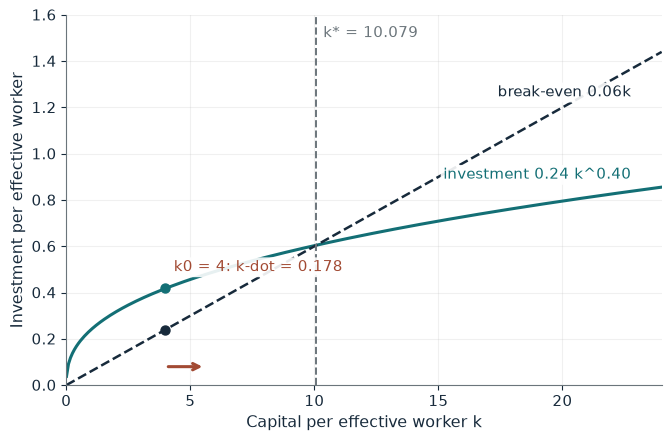

Steady state k*       10.079
Steady output y*      2.520
Output at k0          1.741
Investment at k0      0.418
Break-even at k0      0.240
k-dot                 0.178
k-dot as share of k0  4.45%
Capital               grows

Worked steps:
  1. k* = (0.24 / 0.06)^(1/0.60) = 4^(5/3) = 10.079
  2. y* = 10.079^0.40 = 2.520
  3. Output at k0: 4^0.40 = 1.7411
  4. Investment = 0.24 x 1.7411 = 0.4179
  5. Break-even = 0.06 x 4 = 0.2400
  6. k-dot = 0.4179 - 0.2400 = 0.178, or 4.45% of k0

With s = 0.24 the target is k* = 10.079. At k0 = 4 investment is 0.24 x 1.7411 = 0.4179 and break-even investment is 0.06 x 4 = 0.2400, so k-dot = 0.4179 - 0.2400 = 0.178 (4.45% of k0): investment exceeds break-even needs, so capital per effective worker rises toward k*.


In [2]:
show(solow_picture(s=0.24, k0=4))

Change one input, `k0`, and hold the others at the book's values:

In [3]:
sweep(solow_picture, 'k0', [4, 10.079, 16], {'s': 0.24}, ['Investment at k0', 'Break-even at k0', 'k-dot', 'k-dot as share of k0'])

k0 | Investment at k0 | Break-even at k0 | k-dot | k-dot as share of k0
4 | 0.418 | 0.240 | 0.178 | 4.45%
10.079 | 0.605 | 0.605 | 0.000 | 0.00%
16 | 0.728 | 0.960 | -0.232 | -1.45%


From k = 4 investment 0.418 exceeds break-even 0.240, so k-dot = 0.178 (4.45 percent of k). From k = 16 break-even 0.960 exceeds investment 0.728, so k-dot = -0.232 (-1.45 percent). Both head to k* = 10.079.

## 2. Golden rule: the capital stock that maximizes consumption

With $f(k)=k^{0.40}$ and $n+g+\delta=0.08$, consumption is $c(k)=f(k)-(n+g+\delta)k$ and the golden rule sets the marginal product equal to the break-even rate.

$$0.40k^{-0.60}=0.08, \qquad k_{GR}=5^{1/0.60}\approx14.620.$$

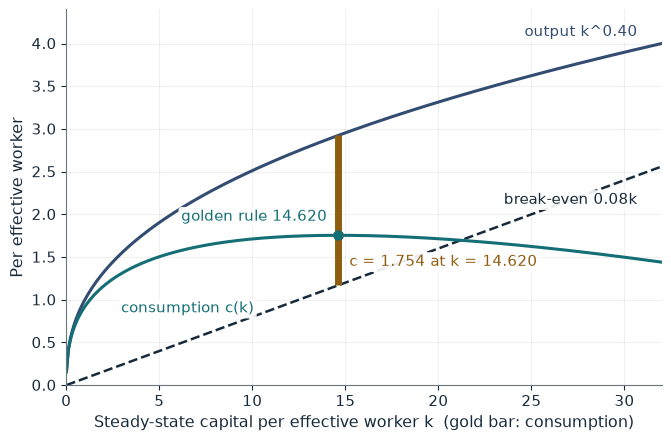

Output                   2.924
Break-even investment    1.170
Consumption              1.754
Saving rate needed       0.400
MPK                      0.080
Golden-rule k            14.620
Golden-rule consumption  1.754
Position                 at the golden rule

Worked steps:
  1. Golden rule: 0.40 k^(-0.60) = 0.08, so k^0.60 = 5.000 and k_GR = 14.620
  2. Output = 14.620^0.40 = 2.9240
  3. Break-even = 0.08 x 14.620 = 1.1696
  4. c = 2.9240 - 1.1696 = 1.754
  5. Saving rate = 1.1696 / 2.9240 = 0.400
  6. MPK = 0.40 x 14.620^(-0.60) = 0.080

At k = 14.620 output is 2.9240 and break-even investment 0.08 x 14.620 = 1.1696, leaving consumption 2.9240 - 1.1696 = 1.754. With n + g + delta = 0.08 the golden-rule stock is 14.620 with consumption 1.754. This k is at the golden rule: MPK equals the break-even rate (difference 0.000 at three decimals), so no steady-state stock gives more consumption.


In [4]:
show(golden_picture(k=14.62, ndg=0.08))

Change one input, `k`, and hold the others at the book's values:

In [5]:
sweep(golden_picture, 'k', [9, 14.62, 25], {'ndg': 0.08}, ['Output', 'Break-even investment', 'Consumption', 'MPK'])

k | Output | Break-even investment | Consumption | MPK
9 | 2.408 | 0.720 | 1.688 | 0.107
14.62 | 2.924 | 1.170 | 1.754 | 0.080
25 | 3.624 | 2.000 | 1.624 | 0.058


Consumption is 1.688 at k = 9, 1.754 at the golden rule and 1.624 at k = 25: output is highest at 25, but consumption is highest at 14.620.

## 3. Conditional convergence: same income, different destinations

Both regions start at 15,000 and $\lambda=0.15$; growth is $g\approx\lambda\ln(y^*/y_0)$.

$$g_E=0.15\ln\left(\frac{30{,}000}{15{,}000}\right)=0.15\ln(2)\approx0.1040$$

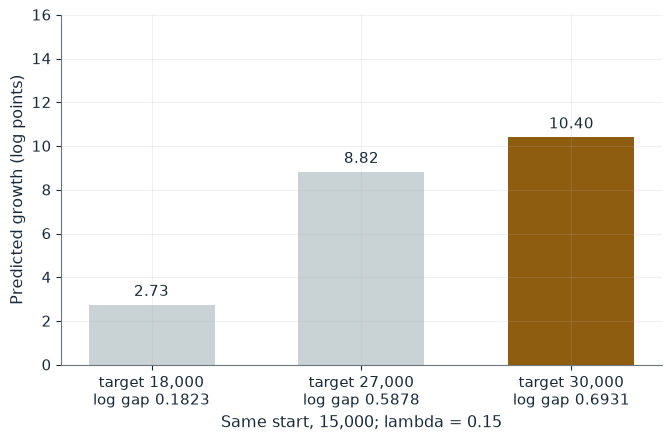

Starting income       15,000
Target income         30,000
Log gap               0.6931
Predicted growth      0.1040
Growth in log points  10.40

Worked steps:
  1. Ratio = 30,000 / 15,000 = 2.0
  2. Log gap = ln(2.0) = 0.69315
  3. g = 0.15 x 0.69315 = 0.1040
  4. In log points: 10.40

Both regions start at 15,000. With target 30,000 and lambda = 0.15, predicted growth is 0.15 x 0.69315 = 0.1040, or 10.40 log points, because ln(2.0) = 0.69315. Across the three targets growth runs from 2.73 to 10.40 log points: equal starting income does not mean equal growth when destinations differ.


In [6]:
show(convergence_picture(y_star=30_000, lam=0.15))

Change one input, `y_star`, and hold the others at the book's values:

In [7]:
sweep(convergence_picture, 'y_star', [18000, 27000, 30000], {'lam': 0.15}, ['Log gap', 'Predicted growth', 'Growth in log points'])

y_star | Log gap | Predicted growth | Growth in log points
18000 | 0.1823 | 0.0273 | 2.73
27000 | 0.5878 | 0.0882 | 8.82
30000 | 0.6931 | 0.1040 | 10.40


Targets 18,000, 27,000 and 30,000 give 2.73, 8.82 and 10.40 log points from the same start. Equal starting income does not mean equal growth.

## 4. Solow residual: what the remainder measures

Output grows 7 percent, capital services 9 percent and labor services 1.5 percent, with $\alpha=0.35$, so $g_A=g_Y-\alpha g_K-(1-\alpha)g_L$.

$$0.35(9)+0.65(1.5)=3.15+0.975=4.125$$

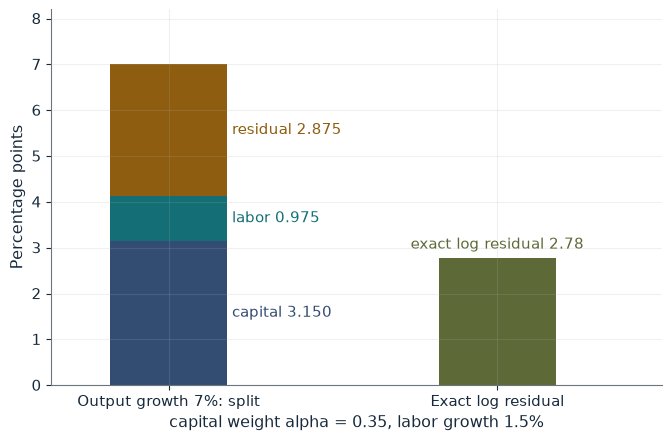

Capital contribution             3.150
Labor contribution               0.975
Measured inputs                  4.125
Residual (points)                2.875
Exact log residual (log points)  2.78

Worked steps:
  1. Capital: 0.35 x 9 = 3.150
  2. Labor: 0.65 x 1.5 = 0.975
  3. Inputs = 3.150 + 0.975 = 4.125
  4. Residual = 7 - 4.125 = 2.875
  5. Exact: ln(1.07) - 0.35 ln(1.09) - 0.65 ln(1.015) = 0.027819

Measured inputs explain 0.35 x 9 + 0.65 x 1.5 = 4.125 points of the 7 percent output growth, leaving a residual of 2.875 points (2.78 log points on exact logs). Faster measured labor growth or a larger capital weight moves part of the remainder into inputs without anything changing in production.


In [8]:
show(residual_picture(gl=1.5, alpha=0.35))

Change one input, `gl`, and hold the others at the book's values:

In [9]:
sweep(residual_picture, 'gl', [1.5, 2.5, 3.5], {'alpha': 0.35}, ['Measured inputs', 'Residual (points)', 'Exact log residual (log points)'])

gl | Measured inputs | Residual (points) | Exact log residual (log points)
1.5 | 4.125 | 2.875 | 2.78
2.5 | 4.775 | 2.225 | 2.14
3.5 | 5.425 | 1.575 | 1.51


The residual is 2.875 points (2.78 log points exactly). A revised labor series at 2.5 percent cuts it to 2.225 points (2.14 log points) with nothing changed in production.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

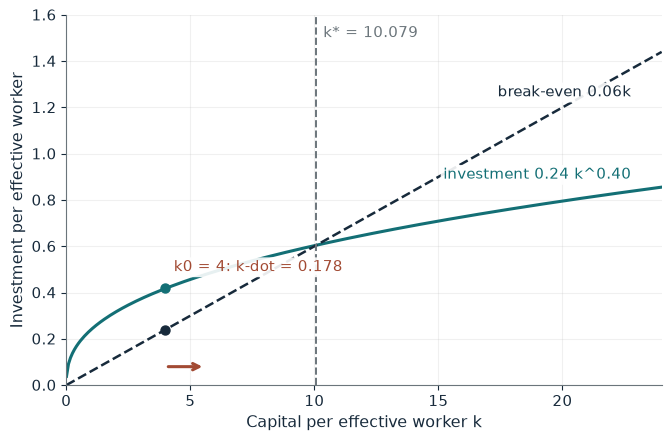

Steady state k*       10.079
Steady output y*      2.520
Output at k0          1.741
Investment at k0      0.418
Break-even at k0      0.240
k-dot                 0.178
k-dot as share of k0  4.45%
Capital               grows

Worked steps:
  1. k* = (0.24 / 0.06)^(1/0.60) = 4^(5/3) = 10.079
  2. y* = 10.079^0.40 = 2.520
  3. Output at k0: 4^0.40 = 1.7411
  4. Investment = 0.24 x 1.7411 = 0.4179
  5. Break-even = 0.06 x 4 = 0.2400
  6. k-dot = 0.4179 - 0.2400 = 0.178, or 4.45% of k0

With s = 0.24 the target is k* = 10.079. At k0 = 4 investment is 0.24 x 1.7411 = 0.4179 and break-even investment is 0.06 x 4 = 0.2400, so k-dot = 0.4179 - 0.2400 = 0.178 (4.45% of k0): investment exceeds break-even needs, so capital per effective worker rises toward k*.


In [10]:
show(solow_picture(s=0.24, k0=4))

## Practice

**1.** With s = 0.24, alpha = 0.40 and n + g + delta = 0.06, what is k-dot at k = 16 as a share of k?

<details><summary>Answer</summary>

Investment 0.24 x 3.0314 = 0.7275 and break-even 0.06 x 16 = 0.9600, so k-dot = -0.232 and -0.232 / 16 = -1.45 percent.

</details>

**2.** At k = 25 with f(k) = k^0.40 and n + g + delta = 0.08, what are consumption and the MPK?

<details><summary>Answer</summary>

3.6239 - 2.0000 = 1.624; MPK = 0.40 x 25^(-0.60) = 0.058, below 0.08, so the stock is above the golden rule.

</details>

**3.** With labor growth 2.5 percent, output 7, capital 9 and alpha 0.35, what is the approximate residual?

<details><summary>Answer</summary>

7 - (0.35 x 9 + 0.65 x 2.5) = 7 - (3.15 + 1.625) = 2.225 points.

</details>